<a href="https://colab.research.google.com/github/Gloou-ui/NM/blob/main/%D0%9B%D0%A08_%D0%9B%D0%B8%D1%82%D0%B2%D0%B8%D0%BD_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

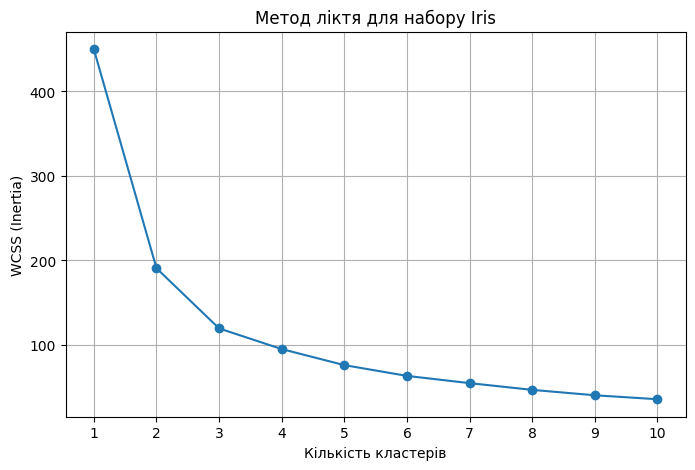

In [3]:
X_iris = iris_df.iloc[:, :3]
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

wcss_iris = []
k_values_iris = range(1, 11)

for k in k_values_iris:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_iris_scaled)
    wcss_iris.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values_iris, wcss_iris, marker="o")
plt.title("Метод ліктя для набору Iris")
plt.xlabel("Кількість кластерів")
plt.ylabel("WCSS (Inertia)")
plt.xticks(list(k_values_iris))
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

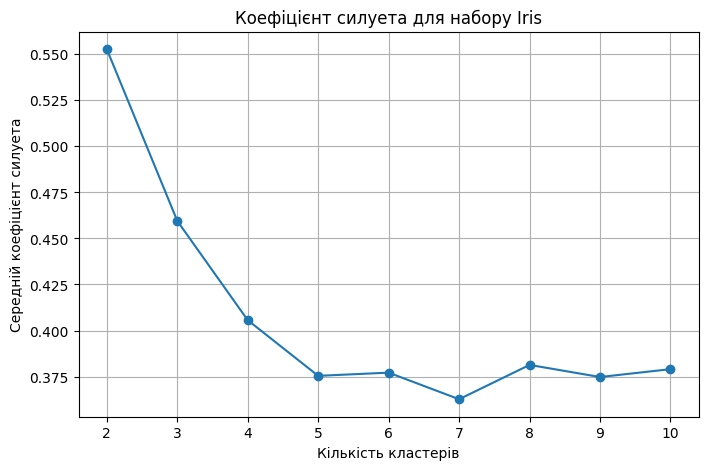

Найкраща кількість кластерів за силуетом: 2
Максимальний коефіцієнт силуета: 0.5525


In [4]:
silhouette_iris = []
k_values_silhouette_iris = range(2, 11)

for k in k_values_silhouette_iris:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_iris_scaled)
    silhouette_iris.append(silhouette_score(X_iris_scaled, labels))

plt.figure(figsize=(8, 5))
plt.plot(k_values_silhouette_iris, silhouette_iris, marker="o")
plt.title("Коефіцієнт силуета для набору Iris")
plt.xlabel("Кількість кластерів")
plt.ylabel("Середній коефіцієнт силуета")
plt.xticks(list(k_values_silhouette_iris))
plt.grid(True)
plt.show()

best_k_silhouette_iris = list(k_values_silhouette_iris)[int(pd.Series(silhouette_iris).idxmax())]
print("Найкраща кількість кластерів за силуетом:", best_k_silhouette_iris)
print("Максимальний коефіцієнт силуета:", round(max(silhouette_iris), 4))

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

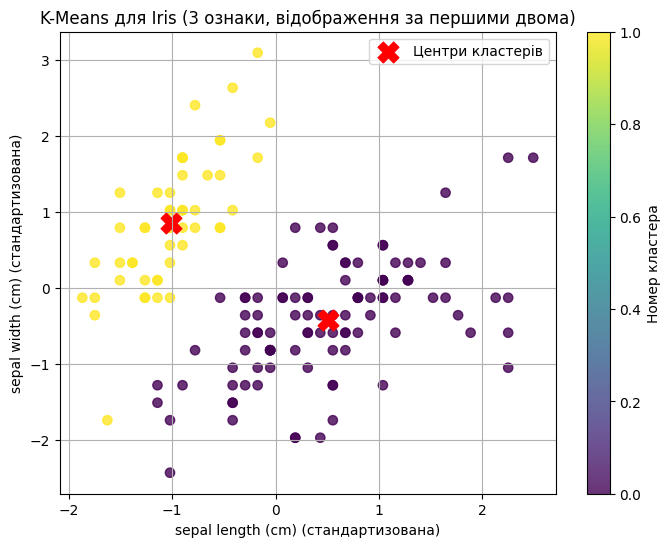

Розмірності для кластеризації: (150, 3)
Кількість об'єктів у кластерах: {0: 100, 1: 50}


In [5]:
kmeans_iris_final = KMeans(n_clusters=2, random_state=42, n_init=10)
iris_clusters = kmeans_iris_final.fit_predict(X_iris_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_iris_scaled[:, 0], X_iris_scaled[:, 1],
    c=iris_clusters, cmap="viridis", s=45, alpha=0.8
)
centers_2d = kmeans_iris_final.cluster_centers_[:, :2]
plt.scatter(centers_2d[:, 0], centers_2d[:, 1],
            c="red", marker="X", s=220, label="Центри кластерів")
plt.title("K-Means для Iris (3 ознаки, відображення за першими двома)")
plt.xlabel(iris_df.columns[0] + " (стандартизована)")
plt.ylabel(iris_df.columns[1] + " (стандартизована)")
plt.legend()
plt.colorbar(scatter, label="Номер кластера")
plt.grid(True)
plt.show()

print("Розмірності для кластеризації:", X_iris_scaled.shape)
print("Кількість об'єктів у кластерах:", pd.Series(iris_clusters).value_counts().sort_index().to_dict())

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

In [6]:
print("Висновок до завдання 1:")
print(
    f"За методом силуетів найкраще значення отримано для {best_k_silhouette_iris} кластерів "
    f"(коефіцієнт {max(silhouette_iris):.3f}). У фінальній моделі за умовою використано "
    "2 кластери. Це спрощене групування; якщо максимум силуета або форма графіка ліктя "
    "вказують на іншу кількість, результати методів не повністю збігаються. "
    "Метод ліктя оцінює зменшення внутрішньокластерної суми квадратів, а силует "
    "— компактність кластерів і їх відокремленість."
)

Висновок до завдання 1:
За методом силуетів найкраще значення отримано для 2 кластерів (коефіцієнт 0.552). У фінальній моделі за умовою використано 2 кластери. Це спрощене групування; якщо максимум силуета або форма графіка ліктя вказують на іншу кількість, результати методів не повністю збігаються. Метод ліктя оцінює зменшення внутрішньокластерної суми квадратів, а силует — компактність кластерів і їх відокремленість.


## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [7]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, silhouette_score
from sklearn.cluster import KMeans

**2.2. Завантаження набору даних онлайн.** Набір даних автоматично завантажується з Kaggle за допомогою `kagglehub`. Завантажувати CSV вручну з комп'ютера не потрібно.

In [8]:
%pip -q install kagglehub

import kagglehub
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")
print("Набір даних завантажено з Kaggle.")
print("Папка з файлами:", path)

csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
print("Знайдені CSV-файли:", [os.path.basename(f) for f in csv_files])

student_csv = next(
    (f for f in csv_files if "student_performance_data" in os.path.basename(f).lower()),
    csv_files[0] if csv_files else None
)
if student_csv is None:
    raise FileNotFoundError("У завантаженому наборі Kaggle не знайдено CSV-файл.")

print("Використовується файл:", os.path.basename(student_csv))

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Набір даних завантажено з Kaggle.
Папка з файлами: /kaggle/input/students-performance-dataset
Знайдені CSV-файли: ['Student_performance_data _.csv']
Використовується файл: Student_performance_data _.csv


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [9]:
df = pd.read_csv(student_csv)
display(df.head())

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [10]:
print("Назви стовпців:")
print(df.columns.tolist())

Назви стовпців:
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [12]:
print("Кількість пропущених значень у кожному стовпці:")
display(df.isna().sum())
print("\nЗагальна кількість пропущених значень:", int(df.isna().sum().sum()))

Кількість пропущених значень у кожному стовпці:


,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0



Загальна кількість пропущених значень: 0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [13]:
print("Кількість повністю дубльованих рядків:", int(df.duplicated().sum()))

Кількість повністю дубльованих рядків: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [14]:
display(df.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.500000,690.655244,1001.000000,1598.750000,2196.500000,2794.250000,3392.000000
Age,2392.0,16.468645,1.123798,15.000000,15.000000,16.000000,17.000000,18.000000
Gender,2392.0,0.510870,0.499986,0.000000,0.000000,1.000000,1.000000,1.000000
Ethnicity,2392.0,0.877508,1.028476,0.000000,0.000000,0.000000,2.000000,3.000000
ParentalEducation,2392.0,1.746237,1.000411,0.000000,1.000000,2.000000,2.000000,4.000000
StudyTimeWeekly,2392.0,9.771992,5.652774,0.001057,5.043079,9.705363,14.408410,19.978094
Absences,2392.0,14.541388,8.467417,0.000000,7.000000,15.000000,22.000000,29.000000
Tutoring,2392.0,0.301421,0.458971,0.000000,0.000000,0.000000,1.000000,1.000000
ParentalSupport,2392.0,2.122074,1.122813,0.000000,1.000000,2.000000,3.000000,4.000000
Extracurricular,2392.0,0.383361,0.486307,0.000000,0.000000,0.000000,1.000000,1.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [15]:
X = df.drop(columns=["GradeClass", "StudentID"])
y = df["GradeClass"]

X = X.apply(pd.to_numeric, errors="coerce")
X = X.fillna(X.median(numeric_only=True))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір X_train:", X_train.shape)
print("Розмір X_test:", X_test.shape)
print("Кількість класів:", y.nunique())

Розмір X_train: (1913, 13)
Розмір X_test: (479, 13)
Кількість класів: 5


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [16]:
rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42, class_weight="balanced"),
    rf_params, cv=5, scoring="accuracy", n_jobs=-1
)
rf_grid.fit(X_train, y_train)
rf_best = rf_grid.best_estimator_
rf_pred = rf_best.predict(X_test)

rf_cv_accuracy = rf_grid.best_score_
rf_test_accuracy = accuracy_score(y_test, rf_pred)

print("Найкращі параметри Random Forest:", rf_grid.best_params_)
print("Середня CV accuracy:", round(rf_cv_accuracy, 4))
print("Тестова accuracy:", round(rf_test_accuracy, 4))

Найкращі параметри Random Forest: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Середня CV accuracy: 0.9289
Тестова accuracy: 0.9248


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [17]:
lr_params = {
    "C": [0.1, 1, 10],
    "penalty": ["l2"],
    "solver": ["saga"],
    "max_iter": [3000]
}
lr_grid = GridSearchCV(
    LogisticRegression(random_state=42, class_weight="balanced"),
    lr_params, cv=5, scoring="accuracy", n_jobs=-1
)
lr_grid.fit(X_train_scaled, y_train)
lr_best = lr_grid.best_estimator_
lr_pred = lr_best.predict(X_test_scaled)

lr_cv_accuracy = lr_grid.best_score_
lr_test_accuracy = accuracy_score(y_test, lr_pred)

print("Найкращі параметри Logistic Regression:", lr_grid.best_params_)
print("Середня CV accuracy:", round(lr_cv_accuracy, 4))
print("Тестова accuracy:", round(lr_test_accuracy, 4))

Найкращі параметри Logistic Regression: {'C': 0.1, 'max_iter': 3000, 'penalty': 'l2', 'solver': 'saga'}
Середня CV accuracy: 0.6461
Тестова accuracy: 0.6388


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [18]:
svm_params = {
    "C": [0.1, 1, 10],
    "kernel": ["linear", "rbf"],
    "gamma": ["scale", "auto"]
}
svm_grid = GridSearchCV(
    SVC(class_weight="balanced"),
    svm_params, cv=5, scoring="accuracy", n_jobs=-1
)
svm_grid.fit(X_train_scaled, y_train)
svm_best = svm_grid.best_estimator_
svm_pred = svm_best.predict(X_test_scaled)

svm_cv_accuracy = svm_grid.best_score_
svm_test_accuracy = accuracy_score(y_test, svm_pred)

print("Найкращі параметри SVM:", svm_grid.best_params_)
print("Середня CV accuracy:", round(svm_cv_accuracy, 4))
print("Тестова accuracy:", round(svm_test_accuracy, 4))

Найкращі параметри SVM: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV accuracy: 0.8014
Тестова accuracy: 0.7871


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [19]:
results = pd.DataFrame({
    "Модель": ["Random Forest", "Logistic Regression", "SVM"],
    "CV accuracy": [rf_cv_accuracy, lr_cv_accuracy, svm_cv_accuracy],
    "Test accuracy": [rf_test_accuracy, lr_test_accuracy, svm_test_accuracy]
}).sort_values("CV accuracy", ascending=False).reset_index(drop=True)

display(results)

best_model_name = results.loc[0, "Модель"]
best_model = {
    "Random Forest": rf_best,
    "Logistic Regression": lr_best,
    "SVM": svm_best
}[best_model_name]

best_prediction = best_model.predict(
    X_test if best_model_name == "Random Forest" else X_test_scaled
)
print("Найкраща модель за CV accuracy:", best_model_name)
print("\nЗвіт класифікації для найкращої моделі:")
print(classification_report(y_test, best_prediction, zero_division=0))

,Модель,CV accuracy,Test accuracy
0,Random Forest,0.928911,0.924843
1,SVM,0.801370,0.787056
2,Logistic Regression,0.646106,0.638831


Найкраща модель за CV accuracy: Random Forest

Звіт класифікації для найкращої моделі:
              precision    recall  f1-score   support

         0.0       1.00      0.52      0.69        21
         1.0       0.91      0.89      0.90        54
         2.0       0.91      0.95      0.93        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.92       479
   macro avg       0.93      0.84      0.87       479
weighted avg       0.93      0.92      0.92       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

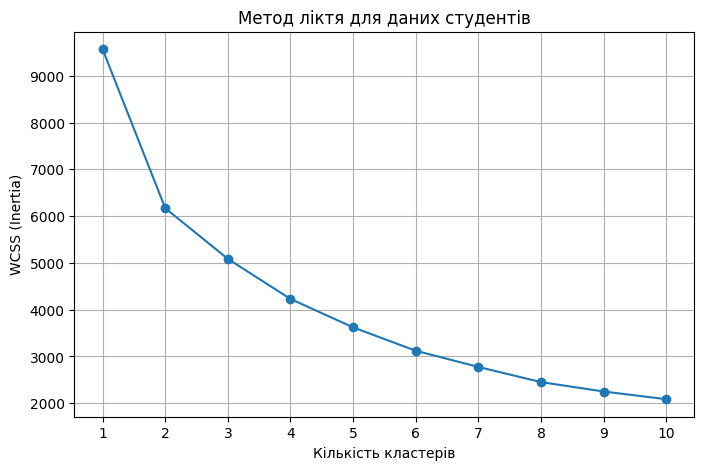

In [20]:
student_cluster_features = ["Age", "StudyTimeWeekly", "Absences", "GPA"]
X_students_cluster = df[student_cluster_features].apply(pd.to_numeric, errors="coerce")
X_students_cluster = X_students_cluster.fillna(X_students_cluster.median())

student_cluster_scaler = StandardScaler()
X_students_scaled = student_cluster_scaler.fit_transform(X_students_cluster)

student_wcss = []
student_k_values = range(1, 11)

for k in student_k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_students_scaled)
    student_wcss.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(student_k_values, student_wcss, marker="o")
plt.title("Метод ліктя для даних студентів")
plt.xlabel("Кількість кластерів")
plt.ylabel("WCSS (Inertia)")
plt.xticks(list(student_k_values))
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

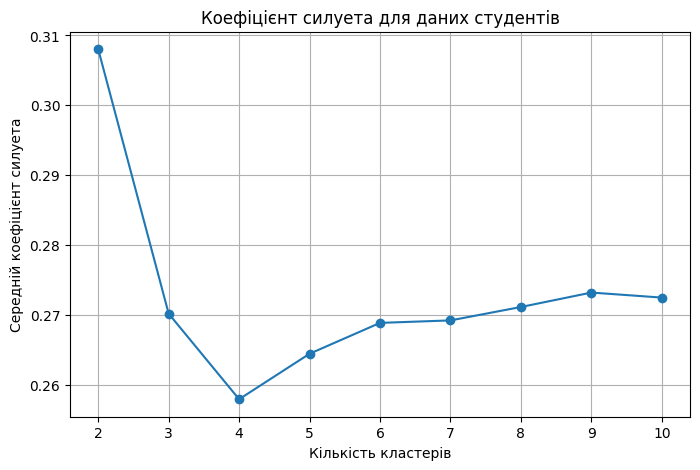

Найкраща кількість кластерів за силуетом: 2
Максимальний коефіцієнт силуета: 0.308


In [21]:
student_silhouette = []
student_silhouette_k = range(2, 11)

for k in student_silhouette_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_students_scaled)
    student_silhouette.append(silhouette_score(X_students_scaled, labels))

plt.figure(figsize=(8, 5))
plt.plot(student_silhouette_k, student_silhouette, marker="o")
plt.title("Коефіцієнт силуета для даних студентів")
plt.xlabel("Кількість кластерів")
plt.ylabel("Середній коефіцієнт силуета")
plt.xticks(list(student_silhouette_k))
plt.grid(True)
plt.show()

best_student_k = list(student_silhouette_k)[int(pd.Series(student_silhouette).idxmax())]
print("Найкраща кількість кластерів за силуетом:", best_student_k)
print("Максимальний коефіцієнт силуета:", round(max(student_silhouette), 4))

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [22]:
%pip -q install kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [23]:
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [24]:
X_pca = df.drop(columns=["StudentID", "GradeClass"]).copy()
X_pca = X_pca.apply(pd.to_numeric, errors="coerce")
X_pca = X_pca.fillna(X_pca.median(numeric_only=True))

print("Кількість ознак для PCA:", X_pca.shape[1])
print("Розмір таблиці:", X_pca.shape)

Кількість ознак для PCA: 13
Розмір таблиці: (2392, 13)


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [25]:
pca_scaler = StandardScaler()
X_pca_scaled = pca_scaler.fit_transform(X_pca)

pca = PCA()
X_pca_all = pca.fit_transform(X_pca_scaled)
explained_variance = pca.explained_variance_ratio_

print("Частка поясненої дисперсії кожної компоненти:")
for i, value in enumerate(explained_variance, start=1):
    print(f"PC{i}: {value:.4f} ({value * 100:.2f}%)")

Частка поясненої дисперсії кожної компоненти:
PC1: 0.1525 (15.25%)
PC2: 0.0861 (8.61%)
PC3: 0.0827 (8.27%)
PC4: 0.0807 (8.07%)
PC5: 0.0786 (7.86%)
PC6: 0.0779 (7.79%)
PC7: 0.0763 (7.63%)
PC8: 0.0760 (7.60%)
PC9: 0.0744 (7.44%)
PC10: 0.0738 (7.38%)
PC11: 0.0717 (7.17%)
PC12: 0.0675 (6.75%)
PC13: 0.0018 (0.18%)


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

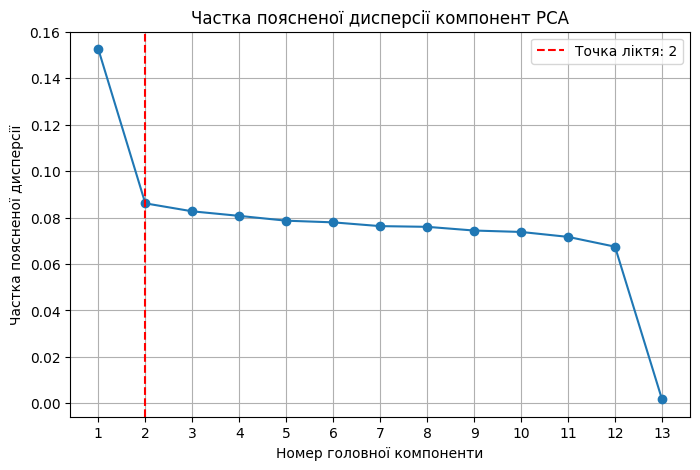

Кількість компонент у точці ліктя: 2


In [26]:
components = np.arange(1, len(explained_variance) + 1)
knee_locator = KneeLocator(
    components, explained_variance,
    curve="convex", direction="decreasing"
)
n_components_knee = knee_locator.elbow

plt.figure(figsize=(8, 5))
plt.plot(components, explained_variance, marker="o")
if n_components_knee is not None:
    plt.axvline(n_components_knee, color="red", linestyle="--",
                label=f"Точка ліктя: {n_components_knee}")
plt.title("Частка поясненої дисперсії компонент PCA")
plt.xlabel("Номер головної компоненти")
plt.ylabel("Частка поясненої дисперсії")
plt.xticks(components)
plt.grid(True)
if n_components_knee is not None:
    plt.legend()
plt.show()

print("Кількість компонент у точці ліктя:", n_components_knee)

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

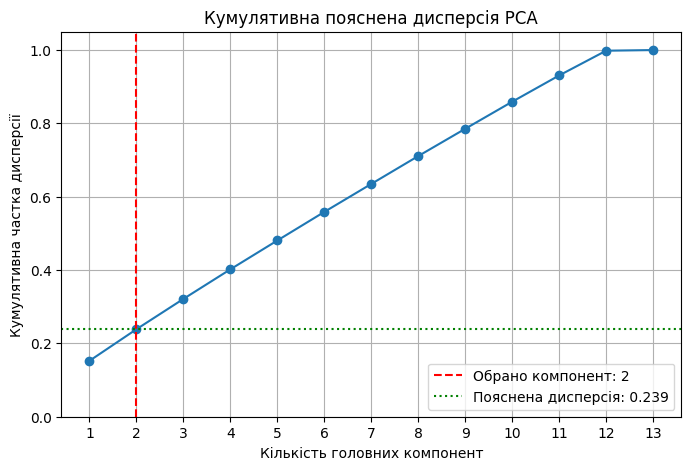

Обрана кількість головних компонент: 2
Кумулятивна пояснена дисперсія: 0.2386 (23.86%)
Розмір даних після PCA: (2392, 2)


In [27]:
cumulative_variance = np.cumsum(explained_variance)
component_counts = np.arange(1, len(cumulative_variance) + 1)

if n_components_knee is None:
    n_components_selected = int(np.argmax(cumulative_variance >= 0.80) + 1)
    print("Точку ліктя автоматично не знайдено; для подальшого PCA обрано мінімальну кількість компонент із поясненням не менше 80% дисперсії.")
else:
    n_components_selected = int(n_components_knee)

explained_by_selected = float(cumulative_variance[n_components_selected - 1])

plt.figure(figsize=(8, 5))
plt.plot(component_counts, cumulative_variance, marker="o")
plt.axvline(n_components_selected, color="red", linestyle="--",
            label=f"Обрано компонент: {n_components_selected}")
plt.axhline(explained_by_selected, color="green", linestyle=":",
            label=f"Пояснена дисперсія: {explained_by_selected:.3f}")
plt.title("Кумулятивна пояснена дисперсія PCA")
plt.xlabel("Кількість головних компонент")
plt.ylabel("Кумулятивна частка дисперсії")
plt.xticks(component_counts)
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()

X_pca_reduced = X_pca_all[:, :n_components_selected]
print("Обрана кількість головних компонент:", n_components_selected)
print(f"Кумулятивна пояснена дисперсія: {explained_by_selected:.4f} ({explained_by_selected * 100:.2f}%)")
print("Розмір даних після PCA:", X_pca_reduced.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [28]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

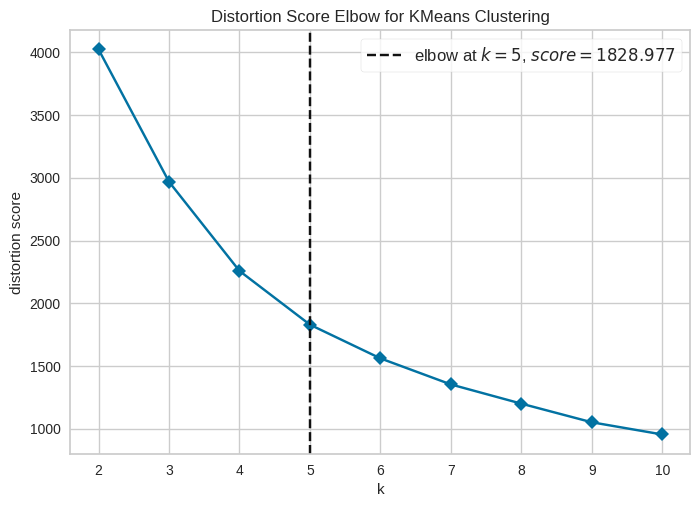

Кількість кластерів за KElbowVisualizer: 5


In [29]:
pca_kmeans = KMeans(random_state=42, n_init=10)
elbow_visualizer = KElbowVisualizer(
    pca_kmeans, k=(2, 11), metric="distortion", timings=False
)
elbow_visualizer.fit(X_pca_reduced)
elbow_visualizer.show()

print("Кількість кластерів за KElbowVisualizer:", elbow_visualizer.elbow_value_)

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

In [30]:
print("ВИСНОВКИ")
print(
    f"1. Для набору Iris кластеризацію виконано методом K-Means за трьома ознаками. "
    f"За методом силуетів найкращий результат відповідає {best_k_silhouette_iris} кластерам; "
    "у фінальній візуалізації за умовою використано 2 кластери."
)
print(
    f"2. Для даних студентів порівняно Random Forest, Logistic Regression і SVM. "
    f"Найкращою за середньою CV accuracy стала модель {best_model_name} "
    f"({results.loc[0, 'CV accuracy']:.4f}); її тестова accuracy становить "
    f"{accuracy_score(y_test, best_prediction):.4f}."
)
print(
    f"3. Класифікація використовує відому цільову змінну GradeClass для навчання "
    "та прогнозування класу. Кластеризація не використовує GradeClass і самостійно "
    "групує студентів за подібністю числових характеристик."
)
print(
    f"4. Для PCA обрано {n_components_selected} головних компонент, які пояснюють "
    f"{explained_by_selected * 100:.2f}% загальної дисперсії. Метод KElbowVisualizer "
    f"після PCA визначив {elbow_visualizer.elbow_value_} кластерів."
)

ВИСНОВКИ
1. Для набору Iris кластеризацію виконано методом K-Means за трьома ознаками. За методом силуетів найкращий результат відповідає 2 кластерам; у фінальній візуалізації за умовою використано 2 кластери.
2. Для даних студентів порівняно Random Forest, Logistic Regression і SVM. Найкращою за середньою CV accuracy стала модель Random Forest (0.9289); її тестова accuracy становить 0.9248.
3. Класифікація використовує відому цільову змінну GradeClass для навчання та прогнозування класу. Кластеризація не використовує GradeClass і самостійно групує студентів за подібністю числових характеристик.
4. Для PCA обрано 2 головних компонент, які пояснюють 23.86% загальної дисперсії. Метод KElbowVisualizer після PCA визначив 5 кластерів.
